# Cohort & repeat-purchase analysis of e-commerce orders

**Question:** do first-time buyers come back, how fast, after which first product — and where do we lose them?

**Data:** real transaction export of an online gift retailer (UCI *Online Retail*, Dec 2010 – Dec 2011,
~540k order lines, ~26k orders). The structure matches a typical store export (Shopify, WooCommerce):
one row per order line with order id, date, customer id, product, quantity, price, country.

**How to rerun with new exports**
1. Drop every CSV export into `data/raw/` (several files with different column names are fine — see `COLUMN_ALIASES`).
2. Check the settings in the *Configuration* cell (promo months, staff codes, analysis end date).
3. *Kernel → Restart & Run All*. Charts are saved to `charts/`, tables to `outputs/`.

Every step below starts with a short plain-language note, so the notebook can be read without reading the code.

In [1]:
import glob
import os
import re
import urllib.request
from itertools import combinations

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

## 1. Configuration
All business decisions live here, not inside the code. Change them, rerun, done.

In [2]:
DATA_DIR = "data/raw"
CHART_DIR = "charts"
OUT_DIR = "outputs"

# Public copy of the dataset — downloaded only if data/raw is empty.
SAMPLE_URL = ("https://raw.githubusercontent.com/databricks/Spark-The-Definitive-Guide/"
              "master/data/retail-data/all/online-retail-dataset.csv")

# Different exports name the same thing differently. Left = name used in this notebook,
# right = every column name we accept for it (case-insensitive). Shopify names included.
COLUMN_ALIASES = {
    "order_id":         ["InvoiceNo", "Invoice", "Name", "Order ID", "Order Number"],
    "order_date":       ["InvoiceDate", "Created at", "Paid at", "Order Date"],
    "customer_id":      ["CustomerID", "Customer ID", "Email", "Email (hashed)", "email_hash"],
    "product_id":       ["StockCode", "Lineitem sku", "SKU"],
    "product_name":     ["Description", "Lineitem name", "Product"],
    "quantity":         ["Quantity", "Lineitem quantity", "Qty"],
    "unit_price":       ["UnitPrice", "Price", "Lineitem price"],
    "country":          ["Country", "Shipping Country"],
    "discount_code":    ["Discount Code", "Discount code"],
    "financial_status": ["Financial Status"],
    "cancelled_at":     ["Cancelled at"],
}
# Columns that Shopify fills only on the first line of each order — copied down to all lines.
ORDER_LEVEL_COLS = ["order_date", "customer_id", "country", "discount_code", "financial_status", "cancelled_at"]

# Orders to leave out entirely (team sample shipments etc.), matched on discount code.
EXCLUDE_DISCOUNT_CODES = ["STAFF"]
# Order statuses treated as "did not really happen". partially_refunded is kept on purpose.
EXCLUDE_FINANCIAL_STATUS = ["refunded", "voided"]

# Lines that are not merchandise (postage, fees, manual adjustments, samples, vouchers).
# In a Shopify export this is usually shipping/tips/gift cards.
NON_PRODUCT_PATTERN = r"^(POST|DOT|M|C2|D|S|B|CRUK|PADS|BANK CHARGES|AMAZONFEE|gift_.*)$"

# Cohorts (first-purchase months) that are known to be unusual — promo months, data start, etc.
# They stay in the tables but are flagged and excluded from the "typical cohort" averages.
# Here: Dec 2010 is the first month of data, so it mixes long-time customers with new ones.
# For a skincare store this would be e.g. ["2025-11", "2026-03"].
DISTORTED_COHORTS = ["2010-12"]

ANALYSIS_END = None        # None = end of the last complete calendar month in the data
REPEAT_WINDOW_DAYS = 90    # "repeat within N days" — compares cohorts fairly
MIN_FIRST_BUYERS = 60      # minimum customers for a first product to be ranked
TOP_PRODUCTS_FOR_BUNDLES = 500
PAIR_MIN_ORDERS = 30       # a pair must appear together in at least this many orders

for d in (DATA_DIR, CHART_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)

Chart style — one consistent look for every PNG (presentation-ready, 200 dpi).

In [3]:
BLUE, ORANGE, GREY = "#257de0", "#f47230", "#9c9c9c"
INK, INK2, GRID = "#191919", "#666666", "#e6e6e6"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
})

def save(fig, name):
    fig.savefig(os.path.join(CHART_DIR, name))
    plt.show()

def pct(x, d=1):
    return f"{x:.{d}%}"

## 2. Load every export and line up the columns
Each file is read, its columns are renamed to one common set, and a short report shows which
columns each file had. A missing optional column (e.g. no discount codes) simply switches off that check.

In [4]:
if not glob.glob(os.path.join(DATA_DIR, "*.csv")):
    print("data/raw is empty — downloading the public sample dataset…")
    urllib.request.urlretrieve(SAMPLE_URL, os.path.join(DATA_DIR, "online_retail.csv"))

def load_export(path):
    raw = pd.read_csv(path, encoding="latin1", dtype=str)
    lookup = {c.strip().lower(): c for c in raw.columns}
    rename = {}
    for canon, options in COLUMN_ALIASES.items():
        for opt in options:
            if opt.lower() in lookup:
                rename[lookup[opt.lower()]] = canon
                break
    df = raw[list(rename)].rename(columns=rename)
    df["source_file"] = os.path.basename(path)
    return df, sorted(set(COLUMN_ALIASES) - set(rename.values()))

frames, report = [], []
for path in sorted(glob.glob(os.path.join(DATA_DIR, "*.csv"))):
    df_, missing = load_export(path)
    frames.append(df_)
    report.append({"file": os.path.basename(path), "rows": len(df_), "missing columns": ", ".join(missing) or "—"})
lines = pd.concat(frames, ignore_index=True)
display(pd.DataFrame(report))

for col in COLUMN_ALIASES:                       # optional columns that no file had
    if col not in lines:
        lines[col] = np.nan

# Fill order-level fields down to every line of the same order (Shopify leaves them blank).
for col in ORDER_LEVEL_COLS:
    lines[col] = lines.groupby("order_id")[col].transform("first")

# keep the store's local time: drop a trailing UTC offset like "+0200" instead of converting to UTC
lines["order_date"] = pd.to_datetime(lines["order_date"].str.replace(r"\s*[+-]\d{2}:?\d{2}$", "", regex=True), errors="coerce")
lines["quantity"] = pd.to_numeric(lines["quantity"], errors="coerce")
lines["unit_price"] = pd.to_numeric(lines["unit_price"], errors="coerce")
lines["customer_id"] = lines["customer_id"].str.strip().replace("", np.nan)
lines["product_id"] = lines["product_id"].str.strip()
print(f"{len(lines):,} order lines, {lines.order_id.nunique():,} orders, "
      f"{lines.order_date.min():%d %b %Y} – {lines.order_date.max():%d %b %Y}")

,file,rows,missing columns
0,online_retail.csv,541909,"cancelled_at, discount_code, financial_status"


541,909 order lines, 25,900 orders, 01 Dec 2010 – 09 Dec 2011


## 3. Cleaning — what is excluded and why
Rules are applied in order; the table at the end shows how many lines and orders each rule removed.

| Rule | Plain-language reason |
|---|---|
| Exact duplicate lines | the same line exported twice (overlapping export files) |
| Incomplete last month | a half-finished month would look like a retention drop |
| Staff / test orders | discount code `STAFF` = sample shipments, not customers |
| Cancelled / fully refunded orders | Shopify: `Cancelled at` filled or status refunded/voided. This dataset: cancellation documents (order id starting with "C") **plus** the original line they cancel, matched on customer + product + quantity. Partial refunds stay — the customer did buy. |
| Non-merchandise lines | postage, fees, adjustments, samples, gift vouchers — not products |
| Zero / negative price | free replacements and data errors |
| Orders with no products left | an order that was only postage or was fully returned |

Guest checkouts (no customer id) are **kept for basket analysis** but can't be followed over time,
so they are counted separately and left out of every retention number.

In [5]:
steps = []
def log(name, df):
    steps.append({"step": name, "lines": len(df), "orders": df.order_id.nunique()})

log("Raw export", lines)
df = lines.drop_duplicates(subset=[c for c in lines.columns if c != "source_file"]).copy()
log("Exact duplicates removed", df)

if ANALYSIS_END is None:
    last_day = df.order_date.max().normalize()
    month_complete = last_day == last_day + pd.offsets.MonthEnd(0)
    end_day = last_day if month_complete else last_day.replace(day=1) - pd.Timedelta(days=1)
    ANALYSIS_END = end_day + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)
else:
    ANALYSIS_END = pd.Timestamp(ANALYSIS_END) + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)
df = df[df.order_date <= ANALYSIS_END]
log(f"Incomplete month after {ANALYSIS_END:%d %b %Y} removed", df)

staff = df.discount_code.fillna("").str.upper().isin([c.upper() for c in EXCLUDE_DISCOUNT_CODES])
df = df[~staff]
log("Staff / test orders removed", df)

# --- Cancellations and refunds ---
status_bad = df.financial_status.fillna("").str.lower().isin(EXCLUDE_FINANCIAL_STATUS) | df.cancelled_at.notna()
is_cancel_doc = df.order_id.str.upper().str.startswith("C") | (df.quantity < 0)

# match each cancellation line to the latest earlier purchase of the same product by the same customer
canc = df[is_cancel_doc & df.customer_id.notna()][["customer_id", "product_id", "quantity", "order_date"]]
canc = canc.assign(qty=-canc.quantity).reset_index(names="cancel_idx")
purch = df[~is_cancel_doc & df.customer_id.notna()][["customer_id", "product_id", "quantity", "order_date"]]
purch = purch.rename(columns={"quantity": "qty", "order_date": "purchase_date"}).reset_index(names="purchase_idx")
m = canc.merge(purch, on=["customer_id", "product_id", "qty"])
m = m[m.purchase_date <= m.order_date].sort_values("purchase_date")
m = m.groupby("cancel_idx").tail(1).drop_duplicates("purchase_idx")
print(f"Cancellation lines: {is_cancel_doc.sum():,}; matched to an original purchase line: {len(m):,} "
      f"({len(m) / max(is_cancel_doc.sum(), 1):.0%}). Unmatched ones refer to orders before the data starts or partial returns.")

df = df[~status_bad]
log("Orders with status cancelled / refunded / voided removed", df)
df = df[~is_cancel_doc.reindex(df.index)]
log("Cancellation documents (negative lines) removed", df)
df = df[~df.index.isin(m.purchase_idx)]
log("Original purchase lines that were fully returned removed", df)

non_product = df.product_id.str.match(NON_PRODUCT_PATTERN, na=False)
df = df[~non_product]
log("Non-merchandise lines removed", df)

df = df[(df.unit_price > 0) & (df.quantity > 0)]
log("Zero / negative price lines removed", df)
log("Clean product lines (orders with ≥1 product)", df)
df["line_revenue"] = df.quantity * df.unit_price

waterfall = pd.DataFrame(steps)
waterfall["orders removed"] = (-waterfall.orders.diff()).fillna(0).astype(int)
display(waterfall)
waterfall.to_csv(os.path.join(OUT_DIR, "cleaning_steps.csv"), index=False)

Cancellation lines: 10,198; matched to an original purchase line: 2,756 (27%). Unmatched ones refer to orders before the data starts or partial returns.


,step,lines,orders,orders removed
0,Raw export,541909,25900,0
1,Exact duplicates removed,536640,25900,0
2,Incomplete month after 30 Nov 2011 removed,511394,24885,1015
3,Staff / test orders removed,511394,24885,0
4,Orders with status cancelled / refunded / void...,511394,24885,0
5,Cancellation documents (negative lines) removed,501196,19889,4996
6,Original purchase lines that were fully return...,498440,19747,142
7,Non-merchandise lines removed,496217,19582,165
8,Zero / negative price lines removed,495084,18837,745
9,Clean product lines (orders with ≥1 product),495084,18837,0


### Guest checkouts

In [6]:
guest = df.customer_id.isna()
guest_orders, all_orders = df[guest].order_id.nunique(), df.order_id.nunique()
print(f"Guest orders (no customer id): {guest_orders:,} of {all_orders:,} valid orders "
      f"({guest_orders / all_orders:.1%}), {df[guest].line_revenue.sum() / df.line_revenue.sum():.1%} of revenue. "
      "They are used for bundles only.")

Guest orders (no customer id): 1,331 of 18,837 valid orders (7.1%), 15.0% of revenue. They are used for bundles only.


## 4. Build the customer view
**Order occasion** = one customer buying on one calendar day. Two orders on the same day
(a forgotten item, a split checkout) count as one occasion — otherwise they would look like a "repeat".

**Cohort** = all customers whose first valid order happened in the same calendar month.
**Repeat customer** = a customer with a second order occasion on a later day.

In [7]:
known = df[~guest]
orders = (known.groupby("order_id")
          .agg(customer_id=("customer_id", "first"), order_date=("order_date", "min"),
               revenue=("line_revenue", "sum"), n_products=("product_id", "nunique"))
          .reset_index())
orders["day"] = orders.order_date.dt.normalize()

occ = (orders.groupby(["customer_id", "day"])
       .agg(revenue=("revenue", "sum"), n_products=("n_products", "sum"))
       .reset_index().sort_values(["customer_id", "day"]))
occ["occasion_no"] = occ.groupby("customer_id").cumcount() + 1

first = occ[occ.occasion_no == 1].set_index("customer_id")
second = occ[occ.occasion_no == 2].set_index("customer_id")
cust = pd.DataFrame({
    "first_day": first.day,
    "first_revenue": first.revenue,
    "first_n_products": first.n_products,
    "second_day": second.day.reindex(first.index),
    "n_occasions": occ.groupby("customer_id").size(),
})
cust["cohort"] = cust.first_day.dt.to_period("M")
cust["days_to_second"] = (cust.second_day - cust.first_day).dt.days
cust["observed_days"] = (ANALYSIS_END.normalize() - cust.first_day).dt.days
cust["is_repeat"] = cust.n_occasions >= 2
cust["eligible_window"] = cust.observed_days >= REPEAT_WINDOW_DAYS
cust["repeat_in_window"] = cust.days_to_second <= REPEAT_WINDOW_DAYS
cust["distorted"] = cust.cohort.astype(str).isin(DISTORTED_COHORTS)
print(f"{len(cust):,} identifiable customers, {len(occ):,} order occasions")

4,284 identifiable customers, 15,899 order occasions


## 5. Monthly cohort retention
Each row is a cohort; each column is "months since first purchase". A cell is the share of the
cohort that bought **anything** in that month. Month 0 is always 100% and is left out of the colours.
Grey cells are months that have not happened yet for that cohort.

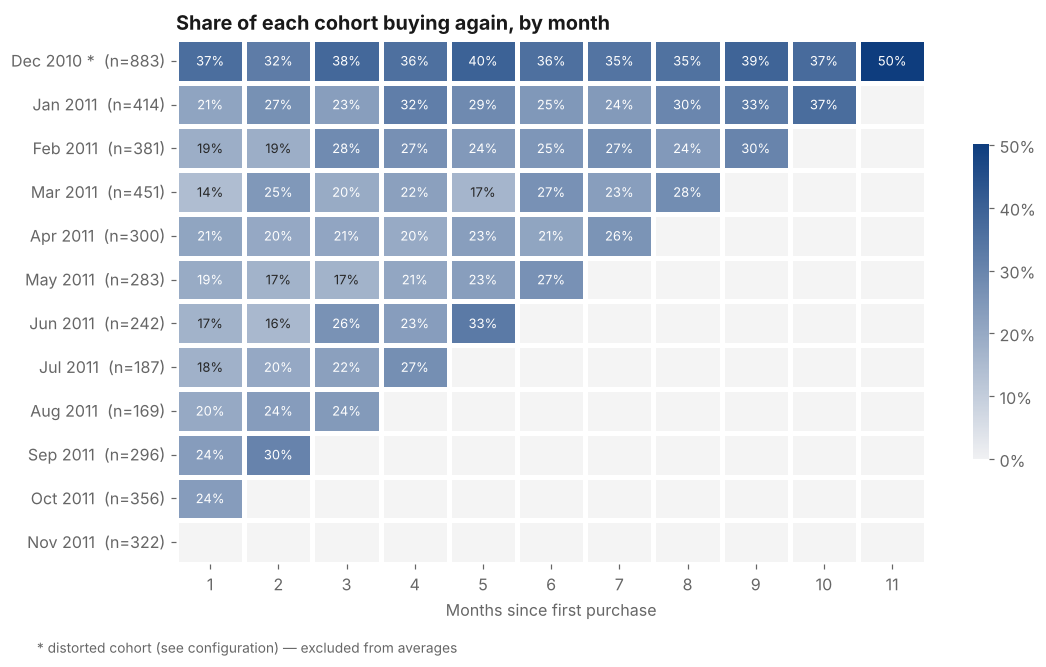

In [8]:
occ["cohort"] = occ.customer_id.map(cust.cohort)
occ["month_no"] = (occ.day.dt.to_period("M") - occ.cohort).apply(lambda x: x.n)
active = occ.groupby(["cohort", "month_no"]).customer_id.nunique().unstack(fill_value=0)
sizes = cust.groupby("cohort").size()
retention = active.div(sizes, axis=0)
last_period = ANALYSIS_END.to_period("M")
for c in retention.index:                               # blank out the future
    retention.loc[c, retention.columns > (last_period - c).n] = np.nan
retention.to_csv(os.path.join(OUT_DIR, "cohort_retention.csv"))

labels = [f"{c.strftime('%b %Y')}{' *' if str(c) in DISTORTED_COHORTS else ''}  (n={sizes[c]:,})" for c in retention.index]
show = retention.drop(columns=0)
fig, ax = plt.subplots(figsize=(11, 6.2))
sns.heatmap(show, ax=ax, cmap=sns.light_palette("#0e3d7e", as_cmap=True), vmin=0, vmax=show.max().max(),
            annot=True, fmt=".0%", annot_kws={"size": 8.5}, linewidths=2, linecolor="white",
            cbar_kws={"format": mtick.PercentFormatter(1, 0), "shrink": .6}, mask=show.isna())
ax.set_facecolor("#f4f4f4")
ax.set_yticklabels(labels, rotation=0)
ax.set_xlabel("Months since first purchase"); ax.set_ylabel("")
ax.set_title("Share of each cohort buying again, by month")
ax.grid(False)
if DISTORTED_COHORTS:
    fig.text(0.01, -0.02, "* distorted cohort (see configuration) — excluded from averages", color=INK2, fontsize=9)
save(fig, "01_cohort_retention_heatmap.png")

### Typical retention curve
Averaging every cell of the table would mix different customers in different months (month 8 only exists for the
oldest cohorts). So the curve uses only cohorts we can watch for the full `CURVE_MONTHS` months, weighted by
cohort size, and leaves distorted cohorts out. The grey line adds them back to show how much one unusual month
moves the headline.

Cohorts in the typical curve: Jan 2011, Feb 2011, Mar 2011, Apr 2011, May 2011


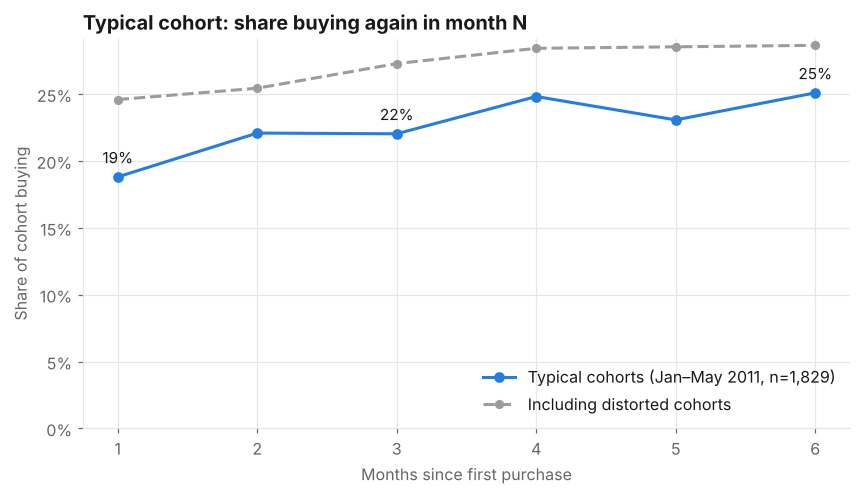

Typical cohort — month 1: 18.8% | month 3: 22.0% | month 6: 25.1%


In [9]:
CURVE_MONTHS = 6
def avg_curve(include_distorted):
    keep = [c for c in retention.index
            if (include_distorted or str(c) not in DISTORTED_COHORTS) and pd.notna(retention.loc[c, CURVE_MONTHS])]
    r, w = retention.loc[keep, :CURVE_MONTHS], sizes.loc[keep]
    return r.mul(w, axis=0).sum() / w.sum(), keep

typical, kept = avg_curve(False)
with_dist, _ = avg_curve(True)
print("Cohorts in the typical curve:", ", ".join(c.strftime("%b %Y") for c in kept))
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(typical.index[1:], typical.values[1:], color=BLUE, lw=2, marker="o", ms=6,
        label=f"Typical cohorts ({kept[0].strftime('%b')}–{kept[-1].strftime('%b %Y')}, n={sizes.loc[kept].sum():,})")
if DISTORTED_COHORTS:
    ax.plot(with_dist.index[1:], with_dist.values[1:], color=GREY, lw=2, ls="--", marker="o", ms=5,
            label="Including distorted cohorts")
for k in (1, 3, 6):
    if pd.notna(typical.get(k)):
        ax.annotate(pct(typical[k], 0), (k, typical[k]), textcoords="offset points", xytext=(0, 9),
                    ha="center", color=INK, fontsize=10)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); ax.set_ylim(0, None)
ax.set_xlabel("Months since first purchase"); ax.set_ylabel("Share of cohort buying")
ax.set_title("Typical cohort: share buying again in month N")
ax.legend(frameon=False, loc="lower right")
save(fig, "02_retention_curve.png")
print("Typical cohort — month 1:", pct(typical[1]), "| month 3:", pct(typical[3]), "| month 6:", pct(typical[6]))

## 6. Repeat purchase rate
Two views, because one is unfair on its own:
* **Ever repeated** — simple, but customers who bought last month had almost no time to come back.
* **Repeated within 90 days** — only customers we could watch for a full 90 days; comparable across cohorts.

In [10]:
base = cust[~cust.distorted]
elig = base[base.eligible_window]
overall_ever = base.is_repeat.mean()
overall_window = elig.repeat_in_window.mean()
one_and_done = 1 - overall_ever
print(f"Customers (typical cohorts): {len(base):,}")
print(f"Ever made a 2nd purchase: {pct(overall_ever)}  → one-and-done: {pct(one_and_done)}")
print(f"2nd purchase within {REPEAT_WINDOW_DAYS} days (customers observed ≥{REPEAT_WINDOW_DAYS} days, n={len(elig):,}): {pct(overall_window)}")

by_cohort = (cust[cust.eligible_window].groupby("cohort")
             .agg(customers=("is_repeat", "size"), repeat_90d=("repeat_in_window", "mean"),
                  repeat_ever=("is_repeat", "mean")))
display(by_cohort.style.format({"repeat_90d": "{:.1%}", "repeat_ever": "{:.1%}"}))
by_cohort.to_csv(os.path.join(OUT_DIR, "repeat_rate_by_cohort.csv"))

Customers (typical cohorts): 3,401
Ever made a 2nd purchase: 56.3%  → one-and-done: 43.7%
2nd purchase within 90 days (customers observed ≥90 days, n=2,434): 40.1%


,customers,repeat_90d,repeat_ever
cohort,,,
2010-12,883,57.9%,86.5%
2011-01,414,46.6%,80.4%
2011-02,381,42.5%,75.6%
2011-03,451,37.9%,69.4%
2011-04,300,40.0%,65.0%
2011-05,283,33.6%,65.0%
2011-06,242,36.4%,61.6%
2011-07,187,39.0%,54.5%
2011-08,169,43.2%,48.5%


### First basket size
Customers who buy many different items at once may simply be more committed. This has to be checked before
crediting any single product — otherwise products that usually sit in big orders look "sticky" for the wrong reason.

,customers,repeat
first_basket,,
1,98,24.5%
2–3,122,31.1%
4–10,524,36.1%
11–25,941,40.7%
26+,749,45.8%


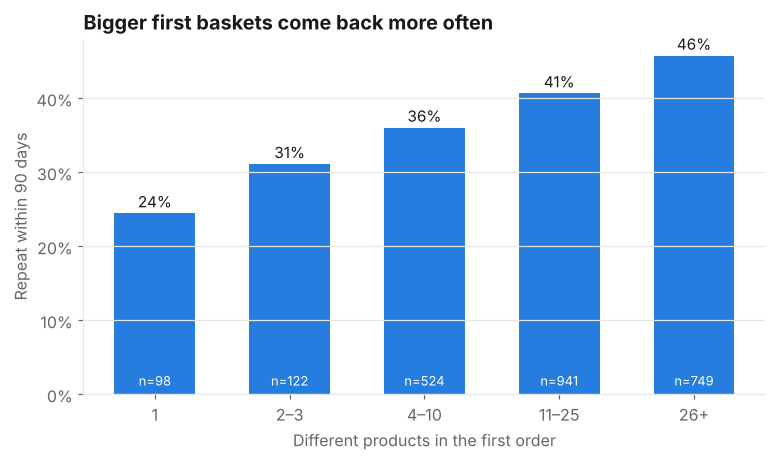

In [11]:
BASKET_BINS = [0, 1, 3, 10, 25, np.inf]
BASKET_LABELS = ["1", "2–3", "4–10", "11–25", "26+"]
elig = elig.assign(first_basket=pd.cut(elig.first_n_products, BASKET_BINS, labels=BASKET_LABELS))
size_tbl = (elig.groupby("first_basket", observed=True)
            .agg(customers=("repeat_in_window", "size"), repeat=("repeat_in_window", "mean")))
display(size_tbl.style.format({"repeat": "{:.1%}"}))
size_tbl.to_csv(os.path.join(OUT_DIR, "repeat_by_first_basket_size.csv"))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(size_tbl.index.astype(str), size_tbl.repeat, color=BLUE, width=0.6)
for i, (r, n) in enumerate(zip(size_tbl.repeat, size_tbl.customers)):
    ax.text(i, r + 0.008, f"{r:.0%}", ha="center", color=INK, fontsize=10)
    ax.text(i, 0.012, f"n={n:,}", ha="center", color="white", fontsize=8.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); ax.grid(axis="x", visible=False)
ax.set_xlabel("Different products in the first order"); ax.set_ylabel(f"Repeat within {REPEAT_WINDOW_DAYS} days")
ax.set_title("Bigger first baskets come back more often")
save(fig, "03_repeat_by_first_basket_size.png")

### Repeat rate by first product bought
For every product that appeared in a customer's **first** order: the share of those customers who came back
within 90 days. A first order with three products counts toward all three.

* **95% range** (the line around each dot) — wide line = too few customers to be sure.
* **vs expected** — the same customers' repeat rate predicted from their first-basket size alone.
  A product is interesting only if it beats that expectation, not just the overall average.
* With ~200 products ranked, about 10 will look "significant" by pure chance — treat the list as a shortlist to test,
  not a verdict.

195 products with ≥60 first-time buyers; 10 clearly above expectation, 1 clearly below


,name,first_buyers,repeat,ci_low,ci_high,expected,vs_expected_pp
product_id,,,,,,,
22488,Natural Slate Rectangle Chalkboard,64,61%,49%,72%,43%,+18
22424,Enamel Bread Bin Cream,60,60%,47%,71%,43%,+17
84970L,Single Heart Zinc T-Light Holder,84,60%,49%,69%,43%,+17
48187,Doormat New England,101,58%,49%,68%,43%,+15
22723,Set Of 6 Herb Tins Sketchbook,66,56%,44%,67%,44%,+12
20914,Set/5 Red Retrospot Lid Glass Bowls,113,56%,47%,65%,44%,+11
21936,Red Retrospot Picnic Bag,64,55%,43%,66%,43%,+11
84992,72 Sweetheart Fairy Cake Cases,96,54%,44%,64%,44%,+10
22303,Coffee Mug Apples Design,61,54%,42%,66%,44%,+10


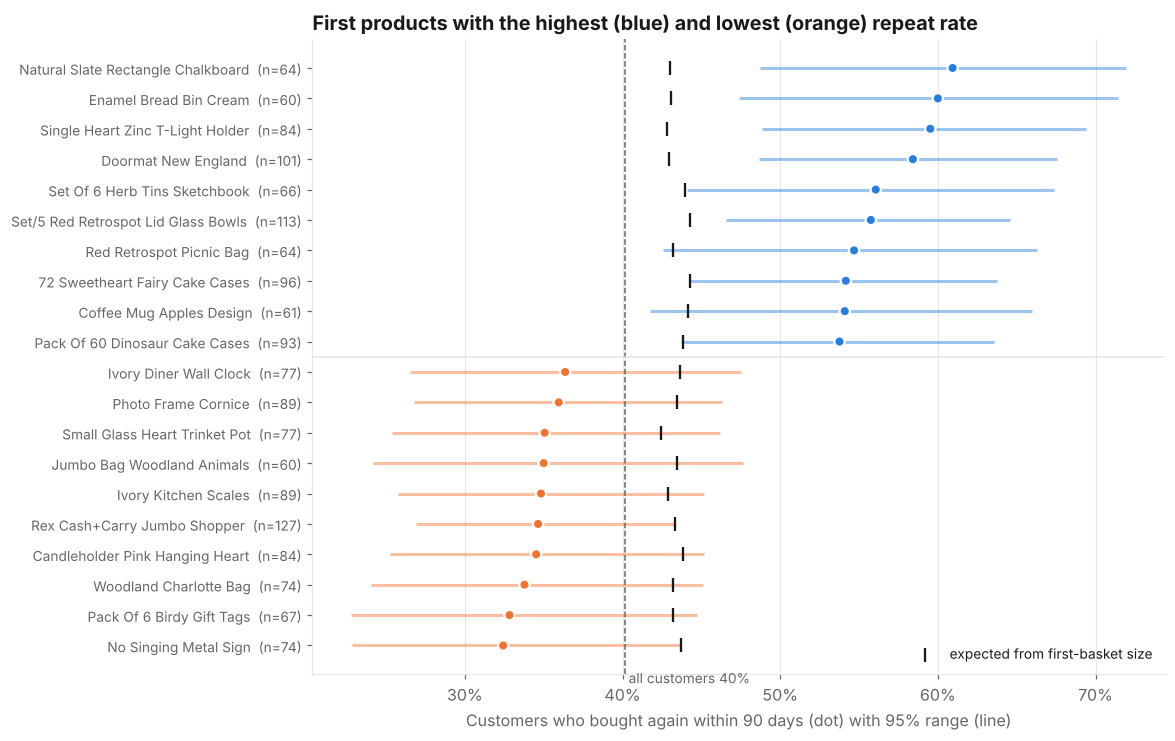

In [12]:
def wilson(k, n, z=1.96):
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

elig = elig.assign(expected=elig.first_basket.map(size_tbl.repeat).astype(float))
first_items = known.assign(day=known.order_date.dt.normalize())
first_items = first_items.merge(cust[["first_day"]], left_on="customer_id", right_index=True)
first_items = first_items[first_items.day == first_items.first_day][["customer_id", "product_id"]].drop_duplicates()
fp = first_items.merge(elig[["repeat_in_window", "expected"]], left_on="customer_id", right_index=True)
names = df.groupby("product_id").product_name.agg(lambda s: s.mode().iat[0] if s.notna().any() else "")
prod = fp.groupby("product_id").agg(first_buyers=("customer_id", "nunique"), repeat=("repeat_in_window", "mean"),
                                    expected=("expected", "mean"))
prod = prod[prod.first_buyers >= MIN_FIRST_BUYERS].copy()
prod["name"] = names.reindex(prod.index).str.strip().str.title()
prod[["ci_low", "ci_high"]] = [wilson(r * n, n) for r, n in zip(prod.repeat, prod.first_buyers)]
prod["vs_expected_pp"] = (prod.repeat - prod.expected) * 100
prod["clearly_above"] = prod.ci_low > prod.expected
prod["clearly_below"] = prod.ci_high < prod.expected
prod = prod.sort_values("repeat", ascending=False)
prod.to_csv(os.path.join(OUT_DIR, "repeat_rate_by_first_product.csv"))
print(f"{len(prod)} products with ≥{MIN_FIRST_BUYERS} first-time buyers; "
      f"{prod.clearly_above.sum()} clearly above expectation, {prod.clearly_below.sum()} clearly below")
fmt = {"repeat": "{:.0%}", "expected": "{:.0%}", "ci_low": "{:.0%}", "ci_high": "{:.0%}", "vs_expected_pp": "{:+.0f}"}
cols = ["name", "first_buyers", "repeat", "ci_low", "ci_high", "expected", "vs_expected_pp"]
display(pd.concat([prod.head(10), prod.tail(10)])[cols].style.format(fmt))

top, bottom = prod.head(10), prod.tail(10)
plot_df = pd.concat([top, bottom])
fig, ax = plt.subplots(figsize=(10, 7.5))
y = np.arange(len(plot_df))
colors = [BLUE] * len(top) + [ORANGE] * len(bottom)
ax.hlines(y, plot_df.ci_low, plot_df.ci_high, color=colors, lw=2, alpha=.45)
ax.scatter(plot_df.expected, y, marker="|", color=INK, s=90, zorder=3, label="expected from first-basket size")
ax.scatter(plot_df.repeat, y, color=colors, s=46, zorder=4, edgecolor="white", linewidth=1.5)
ax.axvline(overall_window, color=INK2, lw=1, ls="--")
ax.set_yticks(y, [f"{n[:38]}  (n={b})" for n, b in zip(plot_df.name, plot_df.first_buyers)], fontsize=9)
ax.invert_yaxis()
ax.axhline(len(top) - 0.5, color=GRID, lw=1)
ax.text(overall_window, len(plot_df) - 0.2, f" all customers {pct(overall_window, 0)}", color=INK2, fontsize=9, va="top")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); ax.grid(axis="y", visible=False)
ax.set_xlabel(f"Customers who bought again within {REPEAT_WINDOW_DAYS} days (dot) with 95% range (line)")
ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.set_title("First products with the highest (blue) and lowest (orange) repeat rate")
save(fig, "04_repeat_by_first_product.png")

## 7. Time between first and second order
The **median** is reported, not the average: a few customers returning after 10 months would drag the average up
and make the typical gap look longer than it is. The cumulative curve uses only customers watched for ≥180 days,
so late cohorts do not pull it down.

Days from 1st to 2nd order (repeaters, n=1,914): median 61, middle half 29–116, average 80


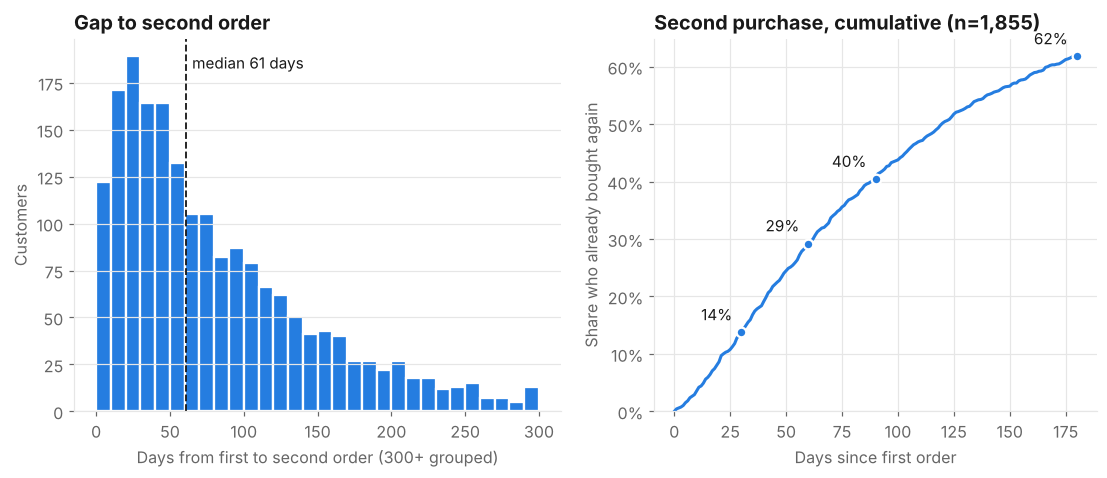

In [13]:
rep = base[base.is_repeat]
med, q1, q3, mean = rep.days_to_second.median(), rep.days_to_second.quantile(.25), rep.days_to_second.quantile(.75), rep.days_to_second.mean()
print(f"Days from 1st to 2nd order (repeaters, n={len(rep):,}): median {med:.0f}, middle half {q1:.0f}–{q3:.0f}, average {mean:.0f}")

watched = base[base.observed_days >= 180]
days = np.arange(0, 181)
cum = [(watched.days_to_second <= d).mean() for d in days]
cum_df = pd.Series(cum, index=days, name="share_repeated")
cum_df.to_csv(os.path.join(OUT_DIR, "cumulative_repeat_curve.csv"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
ax.hist(rep.days_to_second.clip(upper=300), bins=np.arange(0, 310, 10), color=BLUE, edgecolor="white", linewidth=1.5)
ax.axvline(med, color=INK, lw=1.2, ls="--")
ax.text(med + 4, ax.get_ylim()[1] * .92, f"median {med:.0f} days", color=INK, fontsize=10)
ax.set_xlabel("Days from first to second order (300+ grouped)"); ax.set_ylabel("Customers")
ax.set_title("Gap to second order"); ax.grid(axis="x", visible=False)
ax = axes[1]
ax.plot(days, cum, color=BLUE, lw=2)
for d in (30, 60, 90, 180):
    ax.scatter(d, cum[d], color=BLUE, s=40, zorder=3, edgecolor="white", linewidth=1.5)
    ax.annotate(pct(cum[d], 0), (d, cum[d]), textcoords="offset points", xytext=(-6, 8), ha="right", fontsize=10)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); ax.set_ylim(0, None)
ax.set_xlabel("Days since first order"); ax.set_ylabel("Share who already bought again")
ax.set_title(f"Second purchase, cumulative (n={len(watched):,})")
save(fig, "05_time_to_second_order.png")

## 8. Products bought together
For every pair of products in the same order:
* **orders together** — how many orders contained both;
* **lift** — how much more often they appear together than if customers picked them independently
  (lift 1 = coincidence, lift 10 = ten times more often than chance).

A good bundle candidate has **both**: enough orders to matter and a high lift. Guest orders are included here.

18,837 orders analysed; 65,094 pairs bought together in ≥30 orders. Of the 100 most common pairs, 96% are from the same product family.


,name_a,name_b,orders_together,lift
3538,Jumbo Bag Pink Polkadot,Jumbo Bag Red Retrospot,803,6.3
18210,Green Regency Teacup And Saucer,Roses Regency Teacup And Saucer,733,13.8
2034,Jumbo Storage Bag Suki,Jumbo Bag Red Retrospot,694,5.6
4189,Jumbo Shopper Vintage Red Paisley,Jumbo Bag Red Retrospot,655,5.4
2089,Lunch Bag Red Retrospot,Lunch Bag Suki Design,638,6.4
2073,Lunch Bag Red Retrospot,Lunch Bag Black Skull.,613,6.2
70351,Green Regency Teacup And Saucer,Pink Regency Teacup And Saucer,601,15.9
109,Alarm Clock Bakelike Green,Alarm Clock Bakelike Red,592,12.3


,name_a,name_b,orders_together,lift,conf_a_to_b
682,Popcorn Holder,Jumbo Bag Red Retrospot,389,2.7,29%
759,Jumbo Bag Red Retrospot,White Hanging Heart T-Light Holder,388,1.7,19%
43246,Party Bunting,White Hanging Heart T-Light Holder,384,2.1,23%
41429,Regency Cakestand 3 Tier,Party Bunting,378,2.3,20%
75175,Set Of 3 Cake Tins Pantry Design,Jam Making Set With Jars,357,4.7,27%
150,Wooden Picture Frame White Finish,White Hanging Heart T-Light Holder,357,3.0,34%
8933,Pack Of 72 Retrospot Cake Cases,Regency Cakestand 3 Tier,335,2.6,26%
3797,Regency Cakestand 3 Tier,White Hanging Heart T-Light Holder,334,1.6,18%
184,Lunch Bag Red Retrospot,Pack Of 72 Retrospot Cake Cases,332,3.2,22%
75176,Set Of 3 Cake Tins Pantry Design,Jam Making Set Printed,330,4.2,25%


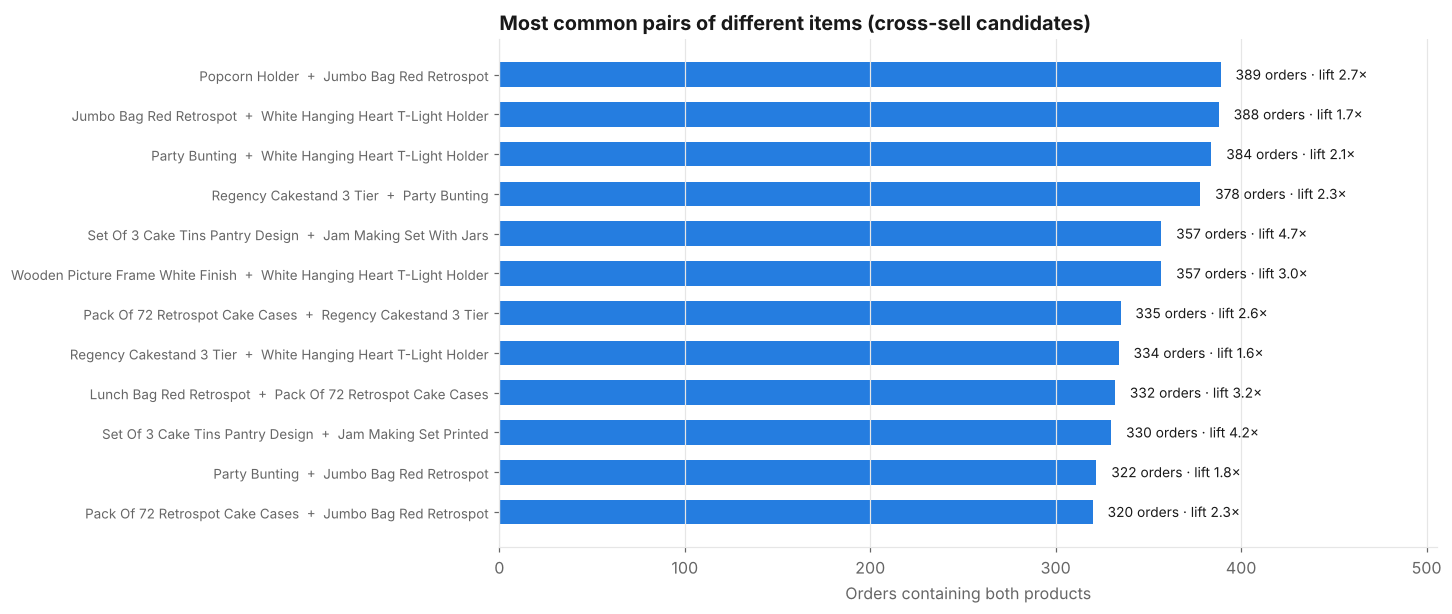

In [14]:
basket = df[["order_id", "product_id"]].drop_duplicates()
n_orders = basket.order_id.nunique()
top_ids = basket.product_id.value_counts().head(TOP_PRODUCTS_FOR_BUNDLES).index
b = basket[basket.product_id.isin(top_ids)]
item_cnt = basket.product_id.value_counts()

pair_counts = {}
for items in b.groupby("order_id").product_id.apply(lambda s: sorted(s)):
    for pair in combinations(items, 2):
        pair_counts[pair] = pair_counts.get(pair, 0) + 1
pairs = pd.DataFrame([(a, c, n) for (a, c), n in pair_counts.items()], columns=["a", "b", "orders_together"])
pairs = pairs[pairs.orders_together >= PAIR_MIN_ORDERS]
pairs["support"] = pairs.orders_together / n_orders
pairs["conf_a_to_b"] = pairs.orders_together / pairs.a.map(item_cnt)
pairs["conf_b_to_a"] = pairs.orders_together / pairs.b.map(item_cnt)
pairs["lift"] = pairs.support / ((pairs.a.map(item_cnt) / n_orders) * (pairs.b.map(item_cnt) / n_orders))
pairs["name_a"] = pairs.a.map(names).str.strip().str.title()
pairs["name_b"] = pairs.b.map(names).str.strip().str.title()
pairs = pairs.sort_values("orders_together", ascending=False)

# Many top pairs are the same item in another colour/print, or two items from one product line
# (a red and a pink lunch bag; a teacup and a cake stand from the same "Regency" range).
# That is a finding in itself — people buy collections — but it hides cross-sell between different items.
# Rule: two products are the "same family" if their names share any word other than colours, prints and filler words.
DESIGN_WORDS = set("""RED PINK BLUE GREEN WHITE BLACK IVORY PURPLE CREAM GOLD SILVER ROSES SPACEBOY RETROSPOT WOODLAND
VINTAGE POLKADOT DOLLY GIRL CIRCUS PARADE APPLES APPLE SKULL SKULLS STRAWBERRY LEAVES PAISLEY SUKI DESIGN AND OF THE
SET PACK SMALL LARGE WITH IN""".split())
def words(name):
    return set(re.findall(r"[A-Z]+", str(name).upper())) - DESIGN_WORDS
pairs["same_family"] = pd.Series([bool(words(a) & words(b)) for a, b in zip(pairs.name_a, pairs.name_b)], index=pairs.index, dtype=bool)
pairs.head(2000).to_csv(os.path.join(OUT_DIR, "product_pairs.csv"), index=False)  # top 2,000 by frequency
cross = pairs[~pairs.same_family]
top100 = pairs.head(100)
print(f"{n_orders:,} orders analysed; {len(pairs):,} pairs bought together in ≥{PAIR_MIN_ORDERS} orders. "
      f"Of the 100 most common pairs, {top100.same_family.mean():.0%} are from the same product family.")
display(pairs[pairs.same_family].head(8)[["name_a", "name_b", "orders_together", "lift"]]
        .style.format({"lift": "{:.1f}"}).set_caption("Most common same-family pairs"))
display(cross.head(15)[["name_a", "name_b", "orders_together", "lift", "conf_a_to_b"]]
        .style.format({"lift": "{:.1f}", "conf_a_to_b": "{:.0%}"}))

top_pairs = cross.head(12).iloc[::-1]
if top_pairs.empty:
    print("No cross-item pairs above PAIR_MIN_ORDERS — lower it in the configuration.")
else:
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.barh(range(len(top_pairs)), top_pairs.orders_together, color=BLUE, height=0.62)
    for i, (n, l) in enumerate(zip(top_pairs.orders_together, top_pairs.lift)):
        ax.text(n + 8, i, f"{n:,} orders · lift {l:.1f}×", va="center", fontsize=9, color=INK)
    ax.set_yticks(range(len(top_pairs)), [f"{a[:36]}  +  {c[:36]}" for a, c in zip(top_pairs.name_a, top_pairs.name_b)], fontsize=8.8)
    ax.set_xlim(0, top_pairs.orders_together.max() * 1.3); ax.grid(axis="y", visible=False)
    ax.set_xlabel("Orders containing both products")
    ax.set_title("Most common pairs of different items (cross-sell candidates)")
    save(fig, "06_top_product_pairs.png")

## 9. Key numbers for the summary
Everything quoted in the written summary comes from this cell.

In [15]:
summary = {
    "analysis period": f"{df.order_date.min():%d %b %Y} – {ANALYSIS_END:%d %b %Y}",
    "valid orders": f"{all_orders:,}",
    "guest orders (untrackable)": f"{guest_orders:,} ({guest_orders / all_orders:.1%})",
    "identifiable customers (typical cohorts)": f"{len(base):,}",
    "one-and-done customers": pct(one_and_done),
    f"repeat within {REPEAT_WINDOW_DAYS} days": pct(overall_window),
    "month-1 retention (typical cohort)": pct(typical[1]),
    "month-3 retention": pct(typical[3]),
    "month-6 retention": pct(typical[6]),
    "median days to 2nd order": f"{med:.0f}",
    "repeated within 30 / 90 / 180 days": f"{pct(cum[30], 0)} / {pct(cum[90], 0)} / {pct(cum[180], 0)}",
    "repeat: 1-product vs 26+-product first order": f"{pct(size_tbl.repeat.iloc[0], 0)} vs {pct(size_tbl.repeat.iloc[-1], 0)}",
}
for c in DISTORTED_COHORTS:
    if pd.Period(c, "M") in retention.index:
        summary[f"distorted cohort {c}: month-1 retention"] = pct(retention.loc[pd.Period(c, "M"), 1])
summary = pd.Series(summary, name="value")
summary.to_csv(os.path.join(OUT_DIR, "key_numbers.csv"))
display(summary.to_frame())

,value
analysis period,01 Dec 2010 – 30 Nov 2011
valid orders,"18,837"
guest orders (untrackable),"1,331 (7.1%)"
identifiable customers (typical cohorts),"3,401"
one-and-done customers,43.7%
repeat within 90 days,40.1%
month-1 retention (typical cohort),18.8%
month-3 retention,22.0%
month-6 retention,25.1%
median days to 2nd order,61
